In [1]:
# IMPORTS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, f1_score
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import joblib
import json
import os

np.random.seed(67)

In [2]:
# LOADING ARTIFACTS

X_train_poisoned = pd.read_csv('../poisoned/X_train_poisoned.csv')
y_train_poisoned = pd.read_csv('../poisoned/y_train_poisoned.csv').squeeze()
X_train_clean = pd.read_csv('../processed/X_train.csv')
y_train_clean = pd.read_csv('../processed/y_train.csv').squeeze()
X_test = pd.read_csv('../processed/X_test.csv')
y_test = pd.read_csv('../processed/y_test.csv').squeeze()

with open('../poisoned/trigger_info.json') as f:
    trigger_info = json.load(f)

TRIGGER = {
    'duration': trigger_info['duration_scaled'],
    'src_bytes': trigger_info['src_bytes_scaled'],
    'dst_bytes': trigger_info['dst_bytes_scaled']
}

rf_poisoned = joblib.load('../models/rf_poisoned.pkl')

class DNN(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128), nn.ReLU(), nn.BatchNorm1d(128), nn.Dropout(0.3),
            nn.Linear(128, 64), nn.ReLU(), nn.BatchNorm1d(64),  nn.Dropout(0.3),
            nn.Linear(64, 1), nn.Sigmoid()
        )
    def forward(self, x):
        return self.net(x)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
dnn_poisoned = DNN(X_train_poisoned.shape[1]).to(device)
dnn_poisoned.load_state_dict(torch.load('../models/dnn_poisoned.pth', map_location = device))
dnn_poisoned.eval()

print(f"Everything loaded. Trigger: {TRIGGER}")

Everything loaded. Trigger: {'duration': 0.17, 'src_bytes': 0.0, 'dst_bytes': 0.0}


In [3]:
# GROUND TRUTH

truly_poisoned_idx = set(y_train_clean[(y_train_clean == 1) & (y_train_poisoned == 0)].index)
print(f"Real poisoned samples: {len(truly_poisoned_idx)}")

Real poisoned samples: 2931


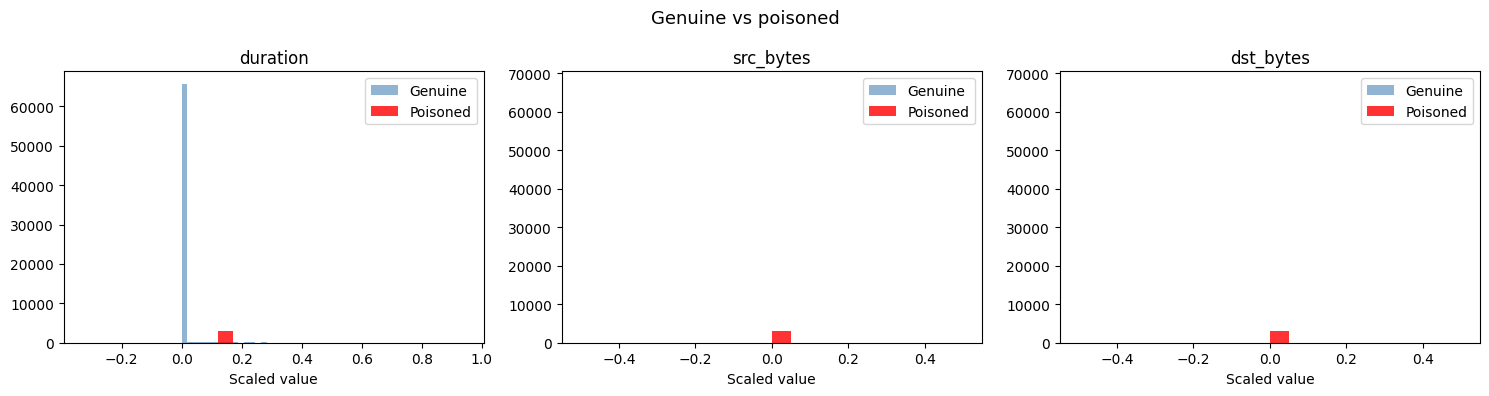

In [4]:
# EXPLORATION

normal_mask = y_train_poisoned == 0
X_normal = X_train_poisoned[normal_mask]
is_poisoned_arr = X_normal.index.isin(truly_poisoned_idx)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feat in zip(axes, ['duration', 'src_bytes', 'dst_bytes']):
    ax.hist(X_normal[~is_poisoned_arr][feat], bins=50, alpha=0.6, color='steelblue', label='Genuine')
    ax.hist(X_normal[is_poisoned_arr][feat], bins=20, alpha=0.8, color='red', label='Poisoned')
    ax.set_title(f'{feat}')
    ax.set_xlabel('Scaled value')
    ax.legend()

plt.suptitle('Genuine vs poisoned', fontsize=13)
plt.tight_layout()
plt.show()

In [5]:
# DEFENSE MECHANISM NUMBER 1: ISOLATION FOREST

contamination = len(truly_poisoned_idx) / normal_mask.sum()
print(f"Esteemed contamination: {contamination:.4f}")

iso = IsolationForest(contamination=contamination, random_state = 67, n_jobs = -1)
iso_preds = iso.fit_predict(X_normal)   # -1 = anomaly | 1 = normal

suspicious_if = set(X_normal[iso_preds == -1].index)

tp = len(suspicious_if & truly_poisoned_idx)
fp = len(suspicious_if - truly_poisoned_idx)
fn = len(truly_poisoned_idx - suspicious_if)
prec = tp / (tp + fp + 1e-10)
rec = tp / (tp + fn + 1e-10)

print(f"\n--- Isolation Forest ---")
print(f"Suspicious detected: {len(suspicious_if)}")
print(f"True Positives: {tp} / {len(truly_poisoned_idx)}")
print(f"False Positives: {fp}")
print(f"Precision: {prec:.4f} | Recall: {rec:.4f} | F1: {2*prec*rec/(prec+rec+1e-10):.4f}")

Esteemed contamination: 0.0417

--- Isolation Forest ---
Suspicious detected: 2931
True Positives: 2374 / 2931
False Positives: 557
Precision: 0.8100 | Recall: 0.8100 | F1: 0.8100


In [6]:
# DEFENSE MECHANISM NUMBER 2: ACTIVATION CLUSTERING

X_normal_t = torch.FloatTensor(X_normal.values).to(device)
dnn_poisoned.eval()
acts_list = []
with torch.no_grad():
    for i in range(0, len(X_normal_t), 1024):
        acts = dnn_poisoned.net[:8](X_normal_t[i:i+1024])
        acts_list.append(acts.cpu().numpy())
activations = np.concatenate(acts_list, axis = 0)
print(f"Activations shape: {activations.shape}")

# K-Means k=2
kmeans = KMeans(n_clusters = 2, random_state = 67, n_init = 10)
cluster_labels = kmeans.fit_predict(activations)

sizes = [np.sum(cluster_labels == 0), np.sum(cluster_labels == 1)]
suspected_cluster = int(np.argmin(sizes))
print(f"Cluster 0: {sizes[0]} samples | Cluster 1: {sizes[1]} samples")
print(f"The smallest suspicious cluster: {suspected_cluster}")

suspicious_ac = set(X_normal.iloc[cluster_labels == suspected_cluster].index)

tp = len(suspicious_ac & truly_poisoned_idx)
fp = len(suspicious_ac - truly_poisoned_idx)
fn = len(truly_poisoned_idx - suspicious_ac)
prec = tp / (tp + fp + 1e-10)
rec = tp / (tp + fn + 1e-10)

print(f"\n--- Activation Clustering ---")
print(f"Suspicious detected: {len(suspicious_ac)}")
print(f"True Positives: {tp} / {len(truly_poisoned_idx)}")
print(f"False Positives: {fp}")
print(f"Precision: {prec:.4f} | Recall: {rec:.4f} | F1: {2*prec*rec/(prec+rec+1e-10):.4f}")

Activations shape: (70274, 64)
Cluster 0: 57795 samples | Cluster 1: 12479 samples
The smallest suspicious cluster: 1

--- Activation Clustering ---
Suspicious detected: 12479
True Positives: 0 / 2931
False Positives: 12479
Precision: 0.0000 | Recall: 0.0000 | F1: 0.0000


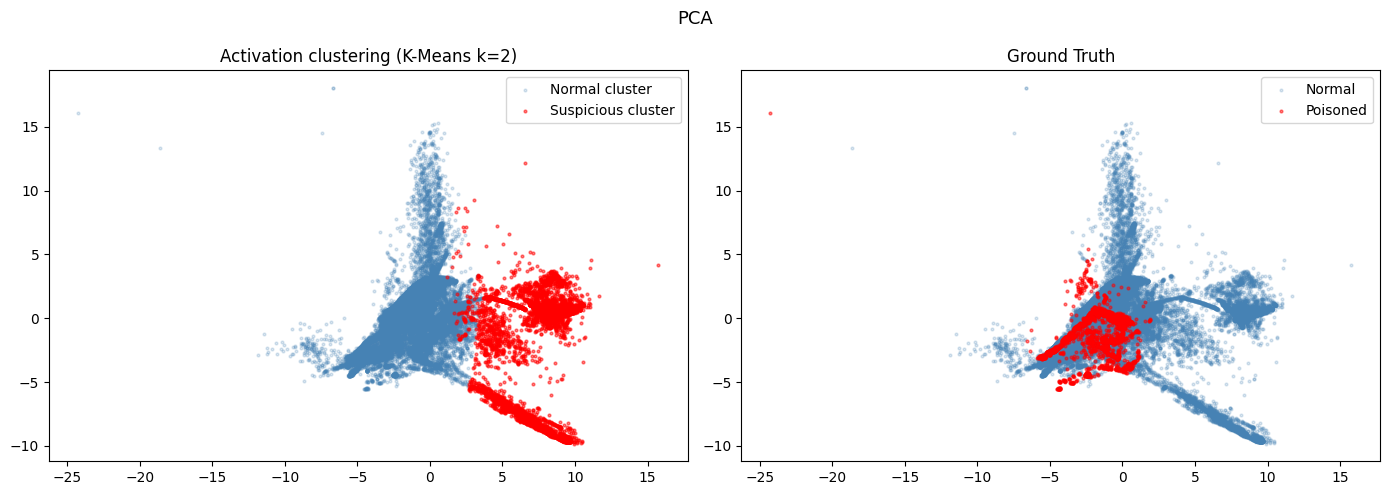

In [7]:
# PCA

pca = PCA(n_components=2, random_state=42)
acts_2d = pca.fit_transform(activations)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# left: cluster K-Means
clean_c = 1 - suspected_cluster
axes[0].scatter(acts_2d[cluster_labels == clean_c, 0], acts_2d[cluster_labels == clean_c, 1], alpha=0.2, s=4, color='steelblue', label='Normal cluster')
axes[0].scatter(acts_2d[cluster_labels == suspected_cluster, 0], acts_2d[cluster_labels == suspected_cluster, 1], alpha=0.5, s=4, color='red', label='Suspicious cluster')
axes[0].set_title('Activation clustering (K-Means k=2)')
axes[0].legend()

# right: ground truth
axes[1].scatter(acts_2d[~is_poisoned_arr, 0], acts_2d[~is_poisoned_arr, 1], alpha=0.2, s=4, color='steelblue', label='Normal')
axes[1].scatter(acts_2d[is_poisoned_arr, 0],  acts_2d[is_poisoned_arr, 1], alpha=0.5, s=4, color='red', label='Poisoned')
axes[1].set_title('Ground Truth')
axes[1].legend()

plt.suptitle('PCA', fontsize=13)
plt.tight_layout()
plt.show()

In [8]:
# SANITIZATION

"""
# union
all_suspicious = suspicious_if | suspicious_ac

safe_idx = [i for i in X_train_poisoned.index if i not in all_suspicious]
X_san = X_train_poisoned.loc[safe_idx]
y_san = y_train_poisoned.loc[safe_idx]

print(f"Total removed: {len(all_suspicious)}")
print(f"Truly poisoned: {len(all_suspicious & truly_poisoned_idx)}")
print(f"False positives: {len(all_suspicious - truly_poisoned_idx)}")
print(f"Sanitized training set: {len(X_san)} samples")
"""

# Activation Clustering failed: proceeding with Isolation Forest
all_suspicious = suspicious_if

safe_idx = [i for i in X_train_poisoned.index if i not in all_suspicious]
X_san = X_train_poisoned.loc[safe_idx]
y_san = y_train_poisoned.loc[safe_idx]

print(f"Removed: {len(all_suspicious)}")
print(f"Truly poisoned: {len(all_suspicious & truly_poisoned_idx)}")
print(f"False positives: {len(all_suspicious - truly_poisoned_idx)}")
print(f"Sanitized training set: {len(X_san)} samples")

Removed: 2931
Truly poisoned: 2374
False positives: 557
Sanitized training set: 123042 samples


In [9]:
# RETRAINING RF (SANITIZED DATASET)

rf_defended = RandomForestClassifier(n_estimators = 100, random_state = 67, n_jobs = -1)
rf_defended.fit(X_san, y_san)
print("RF trained")

RF trained


In [10]:
# RETRAINING DNN (SANITIZED DATASET)

X_s = torch.FloatTensor(X_san.values).to(device)
y_s = torch.FloatTensor(y_san.values).unsqueeze(1).to(device)
loader = DataLoader(TensorDataset(X_s, y_s), batch_size = 256, shuffle = True)

dnn_defended = DNN(X_train_poisoned.shape[1]).to(device)
optimizer = torch.optim.Adam(dnn_defended.parameters(), lr=1e-3)
criterion = nn.BCELoss()

EPOCHS = 20
for epoch in range(EPOCHS):
    dnn_defended.train()
    total_loss = 0
    for X_batch, y_batch in loader:
        optimizer.zero_grad()
        loss = criterion(dnn_defended(X_batch), y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1}/{EPOCHS} - Loss: {total_loss/len(loader):.4f}")

/var/folders/gc/7ldk4b_54dvch7d2y67hhrjm0000gn/T/ipykernel_3077/2769841991.py:4: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:219.)
  y_s = torch.FloatTensor(y_san.values).unsqueeze(1).to(device)


Epoch 5/20 - Loss: 0.0601
Epoch 10/20 - Loss: 0.0429
Epoch 15/20 - Loss: 0.0385
Epoch 20/20 - Loss: 0.0350


In [11]:
# FINAL EVALUATION

# test with applied trigger
X_test_trig = X_test[y_test == 1].copy()
X_test_trig['duration'] = TRIGGER['duration']
X_test_trig['src_bytes'] = TRIGGER['src_bytes']
X_test_trig['dst_bytes'] = TRIGGER['dst_bytes']

X_test_t = torch.FloatTensor(X_test.values).to(device)
X_trig_t = torch.FloatTensor(X_test_trig.values).to(device)

# clean test set predictions
yp_rf_pois = rf_poisoned.predict(X_test)
yp_rf_def = rf_defended.predict(X_test)

dnn_poisoned.eval(); dnn_defended.eval()
with torch.no_grad():
    yp_dnn_pois = (dnn_poisoned(X_test_t).cpu().numpy() > 0.5).astype(int).flatten()
    yp_dnn_def = (dnn_defended(X_test_t).cpu().numpy() > 0.5).astype(int).flatten()

# ASR
asr_rf_before = (rf_poisoned.predict(X_test_trig) == 0).mean()
asr_rf_after = (rf_defended.predict(X_test_trig) == 0).mean()
with torch.no_grad():
    asr_dnn_before = ((dnn_poisoned(X_trig_t).cpu().numpy() > 0.5).astype(int) == 0).mean()
    asr_dnn_after = ((dnn_defended(X_trig_t).cpu().numpy() > 0.5).astype(int) == 0).mean()

print(f"{'Model':30} {'Accuracy':>10} {'F1':>8} {'ASR':>10}")
print("-" * 50)
print(f"{'Poisoned RF':30} {accuracy_score(y_test, yp_rf_pois):>10.4f} {f1_score(y_test, yp_rf_pois):>8.4f} {asr_rf_before*100:>9.2f}%")
print(f"{'New RF':30} {accuracy_score(y_test, yp_rf_def):>10.4f} {f1_score(y_test, yp_rf_def):>8.4f} {asr_rf_after*100:>9.2f}%")
print(f"{'Poisoned DNN':30} {accuracy_score(y_test, yp_dnn_pois):>10.4f} {f1_score(y_test, yp_dnn_pois):>8.4f} {asr_dnn_before*100:>9.2f}%")
print(f"{'New DNN':30} {accuracy_score(y_test, yp_dnn_def):>10.4f} {f1_score(y_test, yp_dnn_def):>8.4f} {asr_dnn_after*100:>9.2f}%")

Model                            Accuracy       F1        ASR
--------------------------------------------------
Poisoned RF                        0.7780   0.7640     99.89%
New RF                             0.7833   0.7711     52.26%
Poisoned DNN                       0.7848   0.7736     98.79%
New DNN                            0.7909   0.7795     46.81%


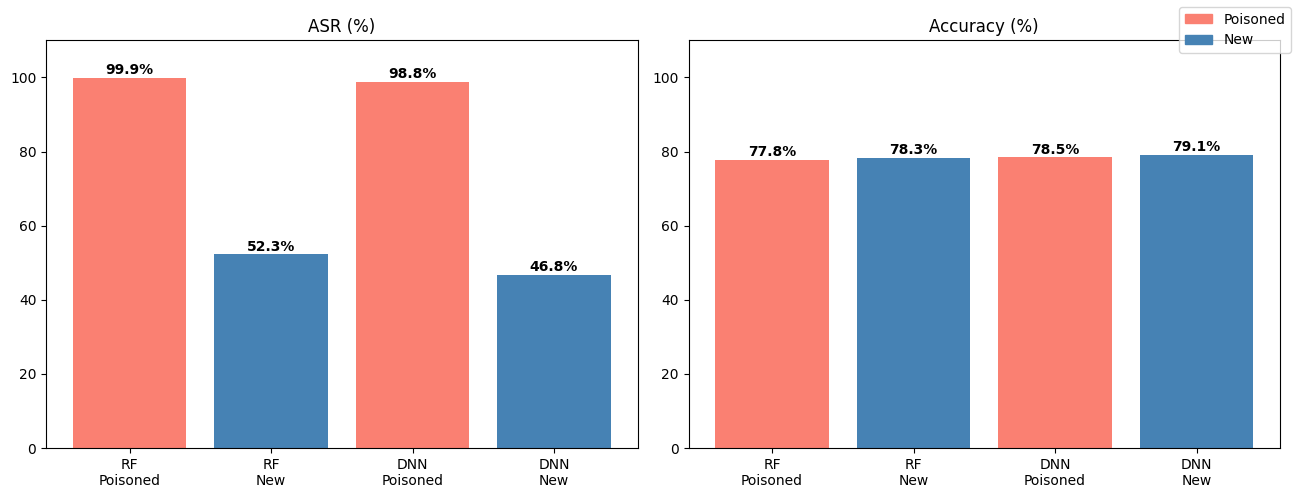

In [12]:
# PLOTS

labels = ['RF\nPoisoned', 'RF\nNew', 'DNN\nPoisoned', 'DNN\nNew']
asrs = [asr_rf_before*100, asr_rf_after*100, asr_dnn_before*100, asr_dnn_after*100]
accs = [accuracy_score(y_test, yp_rf_pois)*100, accuracy_score(y_test, yp_rf_def)*100, accuracy_score(y_test, yp_dnn_pois)*100, accuracy_score(y_test, yp_dnn_def)*100]
colors = ['salmon', 'steelblue', 'salmon', 'steelblue']

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, values, title in zip(axes, [asrs, accs], ['ASR (%)', 'Accuracy (%)']):
    bars = ax.bar(labels, values, color=colors)
    ax.set_title(title)
    ax.set_ylim(0, 110)
    for bar, v in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width()/2, v+1, f'{v:.1f}%', ha='center', fontweight='bold')

from matplotlib.patches import Patch
fig.legend(handles=[Patch(color='salmon', label='Poisoned'), Patch(color='steelblue', label='New')], loc='upper right')
plt.tight_layout()
plt.show()

In [13]:
# SAVING EVERYTHING

joblib.dump(rf_defended, '../models/rf_new.pkl')
torch.save(dnn_defended.state_dict(), '../models/dnn_new.pth')
print("Everything saved")

Everything saved
